In [1]:
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

In [3]:
k_values = [3, 5, 7, 9, 11]
results = {}

rows = []

for weights in ["uniform", "distance"]:
    for k in k_values:
        knn = KNeighborsClassifier(n_neighbors=k, weights=weights)
        scores = cross_val_score(knn, X, y, cv=LeaveOneOut(), scoring="accuracy")
        
        rows.append({
            "k": k,
            "weights": weights,
            "LOO Accuracy": round(scores.mean(), 4),
            "Ошибок (из 150)": len(scores) - int(scores.sum())
        })

df = pd.DataFrame(rows)

pivot = df.pivot(index="k", columns="weights", values="LOO Accuracy")

best_row = df[df["weights"] == "uniform"].sort_values(by="LOO Accuracy", ascending=False).iloc[0]

int(best_row["k"]), best_row["LOO Accuracy"]

(11, np.float64(0.9733))

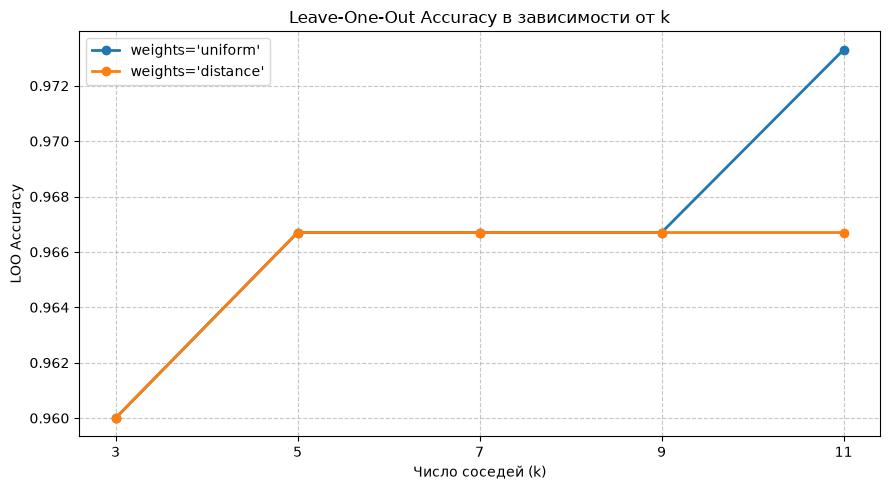

,k,weights,LOO Accuracy,Ошибок (из 150)
0,3,uniform,0.9600,6
1,5,uniform,0.9667,5
2,7,uniform,0.9667,5
3,9,uniform,0.9667,5
4,11,uniform,0.9733,4
5,3,distance,0.9600,6
6,5,distance,0.9667,5
7,7,distance,0.9667,5
8,9,distance,0.9667,5
9,11,distance,0.9667,5


In [4]:
plt.figure(figsize=(9, 5))

for weights in ["uniform", "distance"]:
    subset = df[df["weights"] == weights]
    plt.plot(subset["k"], subset["LOO Accuracy"], marker="o", linewidth=2, label=f"weights='{weights}'")
    
plt.title("Leave-One-Out Accuracy в зависимости от k")
plt.xlabel("Число соседей (k)")
plt.ylabel("LOO Accuracy")
plt.xticks(k_values)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

df